# Lab 1 · Làm quen Colab & quy trình làm việc với AI

**Lập trình xử lý dữ liệu (LTXLDL) · 2627-1 · Giờ thực hành**

Giữ bài làm trong notebook này. Với Colab: **File → Save a copy in Drive** trước khi sửa.
Khi chuyển sang GitHub, nộp đúng file `lab-01.ipynb`; lưu trên Drive chưa phải nộp bài.

## Mục tiêu

1. Chạy, sửa, lưu notebook và tái lập kết quả từ kernel sạch.
2. Giải thích trạng thái biến và thứ tự chạy cell.
3. Đọc bảng, tỷ lệ và biểu đồ trên dữ liệu Airbnb.
4. Thực hiện quy trình: tự phác → hỏi → đọc hiểu → kiểm chứng → khai báo.

## Cách làm việc

- Khởi động và bài có hướng dẫn: tự gõ, **không dùng AI**, theo chính sách môn học.
- Phần **Bài tự làm ✅ mở**: được dùng AI, phải ghi prompt, điều đã kiểm chứng và giới hạn.
- Điền cell **Bài làm** và **Trả lời**. Giữ tên hàm/biến, mã câu và các cell công khai đã cho.
- Public checks chỉ cho biết ví dụ nhỏ đã qua. Grader sẽ dùng dữ liệu khác cùng yêu cầu công khai.
- Cell chưa làm được báo `CHƯA LÀM`; một public check lỗi không dừng các check khác.
  Cơ chế này không che lỗi cú pháp ở cell bài làm: bạn vẫn cần sửa lỗi cú pháp để Run all được.
- **Restart & Run all** trước khi nộp. Việc notebook chạy hết với TODO chưa hoàn thành không có nghĩa bài đã đạt.

## Rubric dự kiến — 100 điểm

| Mục | Điểm | Cách đánh giá |
|---|---:|---|
| Q1: thông tin và dự đoán trạng thái | 15 | Tự động |
| Q2: đọc kết quả bảng hiện tại | 10 | Tự động |
| Q3: tỷ lệ theo loại phòng | 15 | Tự động |
| Giải thích trạng thái và khả năng tái lập | 20 | Giảng viên |
| Diễn giải số liệu, phạm vi kết luận | 15 | Giảng viên |
| Quy trình AI và bài tự chọn | 25 | Giảng viên |

Điểm được tính theo từng mục, không theo số lượng public checks. Phần diễn giải do giảng viên đọc.
Các câu độc lập dự kiến được chấm với đầu vào riêng; không trừ toàn bộ lab vì một hàm trước đó sai.


In [1]:
# Public checks giúp tự kiểm tra; đây không phải điểm chính thức.
# Không sửa cell này trong bài nộp.
PUBLIC_RESULTS = {}

def public_check(case_id, check):
    try:
        check()
    except NotImplementedError:
        status, detail = "CHƯA LÀM", "Điền phần TODO rồi chạy lại."
    except AssertionError as exc:
        status, detail = "CHƯA ĐẠT", str(exc) or "Kết quả chưa khớp ví dụ công khai."
    except Exception as exc:
        status, detail = "LỖI", f"{type(exc).__name__}: {exc}"
    else:
        status, detail = "ĐẠT", "Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric."
    PUBLIC_RESULTS[case_id] = status
    print(f"[{status}] {case_id}: {detail}")

def require_answer(value):
    if value is None or value is Ellipsis:
        raise NotImplementedError

def preview(label, action):
    try:
        value = action()
    except NotImplementedError:
        print(f"{label}: chưa chạy được vì còn TODO.")
    except Exception as exc:
        print(f"{label}: {type(exc).__name__}: {exc}")
    else:
        print(label)
        print(value)

def show_public_summary():
    print("PUBLIC CHECKS — không phải điểm chính thức")
    for case_id, status in PUBLIC_RESULTS.items():
        print(f"{case_id}: {status}")
    print("Sau khi sửa, Restart & Run all để làm mới toàn bộ kết quả.")


## Phần 0 · Khởi động — khoảng 10 phút

Chạy cell bên dưới bằng Shift+Enter. Sửa lời chào, chạy lại và lưu bản sao.
Chưa cần biết pandas hay tự viết hàm ở lab này.


In [2]:
loi_chao = "Xin ch?o l?p LTXLDL, m?nh l? Nguy?n Ti?n Long An."
print(loi_chao)


Xin ch?o l?p LTXLDL, m?nh l? Nguy?n Ti?n Long An.


## Phần 1 · Trạng thái notebook — khoảng 20 phút

**Thí nghiệm A:** Restart session, sau đó thử chạy cell B trước cell A để quan sát `NameError`.
Sau khi quan sát, chạy A rồi B. Lỗi cố ý này chỉ dùng để học; thứ tự lưu trong file vẫn là A → B.


In [3]:
so_phong_gia_dinh = 4  # Cell A


In [4]:
print("Số phòng:", so_phong_gia_dinh)  # Cell B


Số phòng: 4


**Thí nghiệm B:** chạy cell khởi tạo một lần, cell tăng ba lần. Quan sát giá trị.
Sau đó Restart & Run all: cell tăng chỉ chạy một lần. Hai cách chạy khác nhau nên cho kết quả khác nhau.
Câu Q1 hỏi rõ cả hai cách chạy, không so sánh dự đoán với trạng thái ngẫu nhiên còn trong kernel.


In [5]:
dem = 0  # Khởi tạo


In [6]:
dem += 1
print("dem =", dem)


dem = 1


### Q1 · Thông tin và hai dự đoán — 15 điểm

Điền `ten_cua_ban` là chuỗi có ít nhất 2 ký tự sau khi bỏ khoảng trắng đầu/cuối.
`du_doan_3_lan`: giá trị sau khi khởi tạo 0 và tăng 1 đúng ba lần.
`du_doan_run_all`: giá trị khi Restart & Run all với mỗi cell chạy đúng một lần.
Hai dự đoán phải là số nguyên. Được điền số trực tiếp vì mục tiêu ở đây là dự đoán trạng thái.


In [7]:
ten_cua_ban = "Nguy?n Ti?n Long An"
du_doan_3_lan = 3
du_doan_run_all = 1


In [8]:
def check_q1_1():
    require_answer(ten_cua_ban)
    assert isinstance(ten_cua_ban, str) and len(ten_cua_ban.strip()) >= 2, "Kiểm tra tên đã điền."

public_check("Q1 · ví dụ 1", check_q1_1)


[ĐẠT] Q1 · ví dụ 1: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [9]:
def check_q1_2():
    require_answer(du_doan_3_lan)
    require_answer(du_doan_run_all)
    assert type(du_doan_3_lan) is int and type(du_doan_run_all) is int
    assert du_doan_3_lan == 3 and du_doan_run_all == 1, "Đối chiếu số lần thực sự chạy cell tăng."

public_check("Q1 · ví dụ 2", check_q1_2)


[ĐẠT] Q1 · ví dụ 2: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


### Giải thích trạng thái — 20 điểm

Trong 3–5 câu: vì sao B có thể báo `NameError`; vì sao hai cách chạy bộ đếm cho kết quả khác nhau;
và vì sao một notebook chạy được trong phiên hiện tại vẫn có thể lỗi sau restart?
Nêu một thao tác kiểm chứng bạn đã thực hiện. Không cần ảnh chụp màn hình.


**Trả lời của tôi:**

Cell B báo `NameError` nếu chạy trước cell A sau khi khởi động lại kernel, vì biến `so_phong_gia_dinh` chưa được tạo trong phiên mới. Sau khi đặt `dem = 0`, chạy cell tăng ba lần cho kết quả 3; chạy mỗi cell đúng một lần cho kết quả 1. Notebook có thể chạy trong phiên hiện tại nhờ biến còn lưu từ lần chạy trước, nhưng lỗi sau restart nếu thứ tự cell không tạo đủ biến cần dùng. Tôi kiểm chứng độc lập trong một phiên Python mới: đọc biến chưa gán cho `NameError`, rồi tăng bộ đếm theo hai cách lần lượt cho 3 và 1.


## Dữ liệu: thử nhanh và thực hành trên snapshot thật

**Bản nháp mở sẵn bằng 6 dòng giả lập**, chứa giá thiếu và giá bằng 0 để thử quy tắc xử lý.
Không dùng kết quả từ 6 dòng này để kết luận về Santiago.

Khi thực hành trên dữ liệu thật, lấy `listings.csv` bản **visualisations**, Santiago,
snapshot **2026-06-29**, giá **CLP/đêm**, từ [Inside Airbnb](https://data.insideairbnb.com/chile/rm/santiago/2026-06-29/visualisations/listings.csv),
hoặc bản sao cùng snapshot do giảng viên cung cấp. Đưa file vào Colab/Jupyter rồi điền
`LISTINGS_PATH` trong cell dưới. Nếu nguồn tải không hoạt động, không thay bằng snapshot khác
mà không ghi rõ. Đường dẫn là cấu hình dữ liệu thực hành, không phải câu trả lời.

Public checks dùng các bộ dữ liệu nhỏ riêng, nên vẫn chạy được khi chưa có snapshot thật.
Các con số của snapshot gốc không được dùng làm hằng số trong lời giải.


In [10]:
from pathlib import Path
import csv
import io

# Nếu đã có snapshot thật, điền đường dẫn, ví dụ "data/listings.csv".
# Để None khi xem bản nháp: dùng 6 dòng GIẢ LẬP ở dưới, không phải Santiago.
LISTINGS_PATH = "data/listings.csv"
DEMO_CSV = 'id,name,neighbourhood,room_type,price,number_of_reviews,last_review\n1,Phong A,Centro,Entire home/apt,100,0,\n2,Phong B,Centro,Private room,50,2,2026-05-10\n3,Phong C,Norte,Entire home/apt,,0,\n4,Phong D,Norte,Entire home/apt,150,1,2026-06-01\n5,Phong E,Sur,Private room,0,3,2026-05-30\n6,Phong F,Sur,Entire home/apt,300,2,2026-06-10\n'

if LISTINGS_PATH is None:
    rows = list(csv.DictReader(io.StringIO(DEMO_CSV)))
    DATA_LABEL = "GIẢ LẬP — 6 dòng để thử bản nháp"
else:
    with open(LISTINGS_PATH, encoding="utf-8", newline="") as f:
        rows = list(csv.DictReader(f))
    DATA_LABEL = f"File người học cung cấp: {LISTINGS_PATH}"

print(DATA_LABEL)
print("Số dòng:", len(rows))
print(rows[:2])


File người học cung cấp: data/listings.csv
Số dòng: 18534
[{'id': '978070332077815549', 'name': 'luminosa mansarda con balcón', 'host_id': '118157228', 'host_profile_id': '1468207531264648757', 'host_name': 'Patricia', 'neighbourhood_group': '', 'neighbourhood': 'Ñuñoa', 'latitude': '-33.43765', 'longitude': '-70.5833', 'room_type': 'Private room', 'price': '45647', 'minimum_nights': '4', 'number_of_reviews': '2', 'last_review': '2023-12-15', 'reviews_per_month': '0.06', 'calculated_host_listings_count': '5', 'availability_365': '269', 'number_of_reviews_ltm': '0', 'license': ''}, {'id': '1069858035768058539', 'name': 'Cómoda habitación bien ubicada con baño privado', 'host_id': '462786436', 'host_profile_id': '1470084981980135796', 'host_name': 'Luís Alfonso', 'neighbourhood_group': '', 'neighbourhood': 'Recoleta', 'latitude': '-33.42242', 'longitude': '-70.64116', 'room_type': 'Private room', 'price': '19856', 'minimum_nights': '1', 'number_of_reviews': '8', 'last_review': '2026-05-0

Kích thước: (18534, 19)
room_type
Entire home/apt    15004
Private room        3413
Shared room           61
Hotel room            56
Name: count, dtype: int64


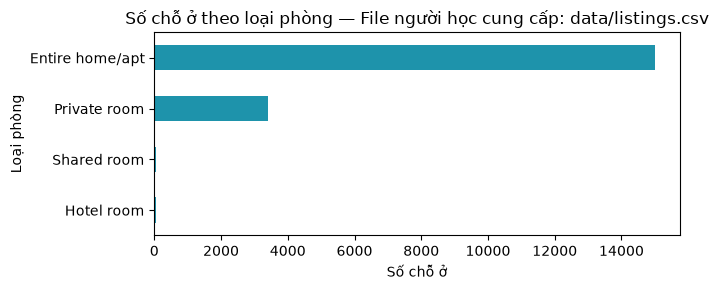

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

ds = pd.DataFrame(rows)
dem_loai = ds["room_type"].value_counts()
print("Kích thước:", ds.shape)
print(dem_loai)
fig, ax = plt.subplots(figsize=(7, 3))
dem_loai.sort_values().plot.barh(ax=ax, color="#1E93AB")
ax.set_title("Số chỗ ở theo loại phòng — " + DATA_LABEL)
ax.set_xlabel("Số chỗ ở")
ax.set_ylabel("Loại phòng")
fig.tight_layout()
plt.show()


### Q2 · Đọc bảng đang sử dụng — 10 điểm

Chạy phần phân tích rồi điền `so_dong` (số nguyên) và `loai_nhieu_nhat` (chuỗi).
Được đọc và điền kết quả ở câu này. Nếu nhiều loại đồng hạng cao nhất, chọn một loại bất kỳ trong số đó.
Khi chuyển từ dữ liệu giả lập sang snapshot thật, đọc lại bảng và cập nhật câu trả lời.


In [12]:
so_dong = 18534
loai_nhieu_nhat = "Entire home/apt"


In [13]:
def check_q2_1():
    require_answer(so_dong)
    assert type(so_dong) is int and so_dong == len(ds), "Đọc số dòng, không lấy số cột."

public_check("Q2 · ví dụ 1", check_q2_1)


[ĐẠT] Q2 · ví dụ 1: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [14]:
def check_q2_2():
    require_answer(loai_nhieu_nhat)
    assert loai_nhieu_nhat in dem_loai.index
    assert dem_loai[loai_nhieu_nhat] == dem_loai.max()

public_check("Q2 · ví dụ 2", check_q2_2)


[ĐẠT] Q2 · ví dụ 2: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


## Phần 3 · Một vòng làm việc với AI ✅ mở — khoảng 25 phút

Nhiệm vụ: tính phần trăm mỗi loại phòng trong bảng đang dùng, làm tròn một chữ số.
Trước khi hỏi AI, lấy số lượng của một loại chia tổng số dòng để ước lượng bằng tay.
Bạn có thể hỏi AI cách làm từ `dem_loai`, nhưng phải đọc hiểu code và kiểm chứng lại.


### Tự phác trước khi hỏi

Ghi loại phòng, tử số, mẫu số và tỷ lệ ước lượng. Sau khi có code, đối chiếu ước lượng với kết quả.


**T? ph?c tr??c khi ch?y l?i ph?p t?nh t? l? tr?n snapshot:**

- `Entire home/apt`: 15.004 / 18.534 ? 81,0%.
- `Private room`: 3.413 / 18.534 ? 18,4%.
- `Shared room`: 61 / 18.534 ? 0,3%.
- `Hotel room`: 56 / 18.534 ? 0,3%.

T?i l?y s? ??m t? b?ng `value_counts()` r?i chia tay cho t?ng s? d?ng tr??c khi ch?y l?i cell t?o `ty_le`. B?n nh?p DEMO tr??c ?? c? t? l? 4/6 v? 2/6; c?c s? ?? kh?ng ?p d?ng cho snapshot.


### Q3 · Tính tỷ lệ bằng code — 15 điểm

Tạo Series `ty_le`, index là các loại phòng có trong `dem_loai`, giá trị là **phần trăm 0–100**,
làm tròn 1 chữ số. Không điền một Series số liệu cố định.
Code phải tính từ `dem_loai` khi bảng đầu vào thay đổi; dữ liệu chấm câu này có ít nhất một dòng,
không thiếu `room_type`. Grader dự kiến thay đầu vào trước khi chạy riêng cell bài làm.


In [15]:
tong_so_dong = dem_loai.sum()
ty_le = (dem_loai / tong_so_dong * 100).round(1)
print(ty_le)


room_type
Entire home/apt    81.0
Private room       18.4
Shared room         0.3
Hotel room          0.3
Name: count, dtype: float64


In [16]:
def check_q3_1():
    require_answer(ty_le)
    assert isinstance(ty_le, pd.Series), "Kết quả cần là Series."
    expected = (dem_loai / dem_loai.sum() * 100).round(1)
    pd.testing.assert_series_equal(ty_le.sort_index(), expected.sort_index(), check_names=False, check_dtype=False)

public_check("Q3 · ví dụ 1", check_q3_1)


[ĐẠT] Q3 · ví dụ 1: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


### Diễn giải — 15 điểm

Viết 3–5 câu: loại nào chiếm tỷ trọng lớn nhất trong **bảng bạn đang dùng**, bằng chứng là gì?
Vì sao tỷ trọng chỗ ở niêm yết không đồng nghĩa với tỷ trọng lượt đặt phòng?
Nếu đang dùng bộ giả lập, ghi rõ không thể suy rộng kết quả sang Santiago.


**Tr? l?i c?a t?i:**

Tr?n snapshot Santiago ng?y 29/06/2026, `Entire home/apt` chi?m t? tr?ng l?n nh?t: 15.004/18.534 ch? ?, t??ng ???ng 81,0%; `Private room` ??ng sau v?i 3.413 ch? ?, t??ng ???ng 18,4%. Hai lo?i c?n l?i l? `Shared room` (61) v? `Hotel room` (56), m?i lo?i kho?ng 0,3% sau l?m tr?n. ??y l? **t? tr?ng tin ??ng**, kh?ng ph?i t? tr?ng l??t ??t ph?ng: m?t tin ??ng c? th? ???c ??t nhi?u l?n ho?c kh?ng ???c ??t l?n n?o. C?n d? li?u giao d?ch ho?c m?t bi?n ??i di?n ???c ki?m ch?ng m?i ??c l??ng ???c ho?t ??ng ??t ph?ng; ri?ng b?ng listings kh?ng cho ph?p suy ra ch? ti?u ??.


## Bài tự làm ✅ mở — cùng khai báo AI chiếm 25 điểm

Chọn một câu hỏi khác trên bảng (ví dụ quận nào có nhiều chỗ ở nhất). Nộp:
**câu hỏi → dự đoán → code → kết quả → kiểm chứng và giới hạn**.
Điền hàm E1 bên dưới để tạo kết quả; ghi giải thích bằng Markdown. Khai báo prompt ở cuối notebook.

Giảng viên chấm dự đoán trước khi hỏi (5), đọc hiểu/code và kết quả (5), kiểm chứng có bằng chứng (10),
khai báo trung thực và giới hạn (5). Không bắt buộc AI phải mắc lỗi; nếu chưa thấy lỗi, nói rõ đã kiểm gì.

**Tự làm thêm, không tính điểm bản nháp:** cài Python và VS Code trên máy, tạo venv và ghi phiên bản Python.


**Tr? l?i c?a t?i ? c?u h?i t? ch?n E1:**

1. **C?u h?i:** Qu?n n?o c? nhi?u ch? ? ni?m y?t nh?t trong snapshot Santiago ng?y 29/06/2026?
2. **D? ?o?n tr??c ??y:** ? b?n nh?p DEMO, t?i ?? d? ?o?n `Centro` ??ng ??u v? l? khu trung t?m; k?t qu? DEMO cho th?y ba khu gi? l?p h?a nhau. Snapshot th?t kh?ng c? qu?n t?n `Centro`, n?n d? ?o?n n?y kh?ng th? coi l? d? ?o?n ri?ng cho snapshot.
3. **Code v? k?t qu?:** `analyze_question(data)` d?ng `value_counts()` tr?n c?t `neighbourhood` r?i tr? b?ng `quan`, `so_cho_o`. Tr?n snapshot 18.534 d?ng, `Santiago` ??ng ??u v?i **7.182** ch? ? (kho?ng **38,8%**), k? ??n l? `Providencia` **2.997** v? `Las Condes` **2.862**. H?m t?nh t? tham s? `data`, kh?ng s?a b?ng g?c; ??u v?o r?ng v?n tr? b?ng r?ng ??ng hai c?t.
4. **Ki?m ch?ng:** ??m ??c l?p b?ng `csv.DictReader` v? `collections.Counter` tr?n file ngu?n c?ng cho `Santiago: 7.182`, `Providencia: 2.997`, `Las Condes: 2.862`. T?ng s? ??m c?a 31 qu?n b?ng 18.534, ??ng s? d?ng CSV; kh?ng c? d?ng thi?u `neighbourhood`. Hai public checks c?a E1 ??u ??t, nh?ng ch? ki?m h?p ??ng h?m n?n ph?p ??m ??c l?p m?i l? ??i chi?u gi? tr?.
5. **Gi?i h?n:** ??y l? s? **listing hi?n di?n ? m?c ch?p**, kh?ng ph?i l??ng ??t ph?ng hay m?c ?? y?u th?ch c?a kh?ch. K?t qu? c? th? ??i ? snapshot kh?c v? ch? ?p d?ng cho Santiago c?a file ngu?n n?y.


### E1 · Câu hỏi tự chọn: đóng gói kết quả phân tích

Chọn câu hỏi khác Q3 trên bảng đang dùng, ví dụ **quận nào có nhiều chỗ ở nhất**.
Giảng viên đã cho phần khai báo hàm để bạn chỉ cần điền thân hàm; chưa yêu cầu thiết kế chương trình phức tạp.
Mục này vẫn thuộc 25 điểm bài mở/quy trình AI, không thêm điểm hay thu hẹp câu hỏi vào một đáp án cố định.

**Hàm:** `analyze_question(data: pd.DataFrame) -> dict`.

- `data`: bảng listings đã nạp; có các cột được giới thiệu trong lab. Cột `price`, `number_of_reviews`
  ở dạng chuỗi như CSV; nếu dùng chúng, bạn tự chuyển kiểu. Grader có thể thay các dòng dữ liệu,
  vì vậy phải tính từ tham số `data`, không đọc biến `ds` bên ngoài hoặc tải dữ liệu khác trong hàm.
- Trả dict có **đúng ba khóa**: `question` (chuỗi câu hỏi không rỗng),
  `table` (DataFrame kết quả, ít nhất một cột, tên cột là các chuỗi không rỗng và không trùng),
  `unit` (chuỗi mô tả đơn vị, ví dụ `"chỗ ở"`, `"%"`, `"CLP/đêm"`).
- Bạn chọn schema các cột và ghi rõ ở ô mô tả dưới đây. Kết quả một con số vẫn đóng gói thành bảng 1 dòng.
  Với dữ liệu đầu vào rỗng, trả bảng 0 dòng có cùng các cột đã khai báo.
- Không sửa `data` tại chỗ; không `print`, không vẽ hoặc ghi file trong hàm. Hiển thị kết quả ở cell riêng.
- Public checks chỉ kiểm tra hợp đồng chung và việc không sửa đầu vào. **Chúng không xác nhận kết luận đúng**:
  câu hỏi tự chọn vẫn cần giảng viên đối chiếu phép tính, bằng chứng và giới hạn.

Sau khi chọn câu hỏi, bạn có thể tự tạo bảng vài dòng và tính tay để kiểm tra giá trị của `table`.
Nếu muốn chấm hoàn toàn bằng hidden tests sau này, giảng viên cần chốt loại câu hỏi và schema cụ thể.


In [17]:
def analyze_question(data: pd.DataFrame) -> dict:
    dem_quan = data["neighbourhood"].value_counts()
    bang_ket_qua = pd.DataFrame({
        "quan": dem_quan.index.astype(str),
        "so_cho_o": dem_quan.values
    })

    return {
        "question": "Quận nào có nhiều chỗ ở niêm yết nhất?",
        "table": bang_ket_qua,
        "unit": "chỗ ở"
    }

In [18]:
def check_e1_1():
    sample = pd.DataFrame([
        {"id": "1", "name": "A", "neighbourhood": "X", "room_type": "Private room", "price": "10", "number_of_reviews": "0", "last_review": ""},
        {"id": "2", "name": "B", "neighbourhood": "X", "room_type": "Entire home/apt", "price": "20", "number_of_reviews": "1", "last_review": "2026-01-01"},
        {"id": "3", "name": "C", "neighbourhood": "Y", "room_type": "Private room", "price": "30", "number_of_reviews": "2", "last_review": "2026-01-02"},
    ])
    before = sample.copy(deep=True)
    result = analyze_question(sample)
    assert isinstance(result, dict) and set(result) == {"question", "table", "unit"}
    assert isinstance(result["question"], str) and result["question"].strip()
    assert isinstance(result["unit"], str) and result["unit"].strip()
    table = result["table"]
    assert isinstance(table, pd.DataFrame) and len(table.columns) >= 1
    assert table.columns.is_unique
    assert all(isinstance(c, str) and c.strip() for c in table.columns)
    pd.testing.assert_frame_equal(sample, before)

public_check("E1 · mở rộng · ví dụ 1", check_e1_1)


[ĐẠT] E1 · mở rộng · ví dụ 1: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [19]:
def check_e1_2():
    sample = pd.DataFrame(rows[:2])
    full = analyze_question(sample)
    empty = analyze_question(sample.iloc[:0].copy())
    assert isinstance(empty, dict) and set(empty) == {"question", "table", "unit"}
    assert isinstance(empty["table"], pd.DataFrame)
    assert empty["table"].empty
    assert list(empty["table"].columns) == list(full["table"].columns)
    assert isinstance(empty["question"], str) and empty["question"].strip()
    assert isinstance(empty["unit"], str) and empty["unit"].strip()

public_check("E1 · mở rộng · ví dụ 2", check_e1_2)


[ĐẠT] E1 · mở rộng · ví dụ 2: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [20]:
def show_my_analysis():
    result = analyze_question(ds)
    print("Câu hỏi:", result["question"], "| Đơn vị:", result["unit"])
    return result["table"]

preview("Kết quả câu hỏi tự chọn", show_my_analysis)


Câu hỏi: Quận nào có nhiều chỗ ở niêm yết nhất? | Đơn vị: chỗ ở
Kết quả câu hỏi tự chọn
                   quan  so_cho_o
0              Santiago      7182
1           Providencia      2997
2            Las Condes      2862
3                 Ñuñoa      1813
4          Lo Barnechea       824
5      Estación Central       440
6            La Florida       381
7              Vitacura       351
8              Recoleta       269
9                 Macul       204
10           San Miguel       185
11        Independencia       155
12             La Reina       146
13                Maipú       100
14          La Cisterna        96
15             Pudahuel        93
16          San Joaquín        88
17            Peñalolén        86
18        Quinta Normal        59
19           Huechuraba        51
20            Quilicura        34
21                Renca        33
22             Conchalí        19
23             Lo Prado        18
24            Cerrillos        16
25            La Granja     

**M? t? c?u h?i v? ??u ra c?a t?i:**

- **C?u h?i:** Qu?n n?o c? nhi?u ch? ? ni?m y?t nh?t trong snapshot Santiago 29/06/2026?
- **??u v?o:** c?t `neighbourhood` c?a b?ng listings.
- **??u ra:** `quan` l? t?n qu?n d?ng chu?i; `so_cho_o` l? s? listing d?ng s? nguy?n, s?p gi?m d?n. `unit = "ch? ?"`.
- **Gi? tr? thi?u:** `value_counts()` m?c ??nh b? `NaN`; b?ng r?ng v?n tr? `DataFrame` r?ng v?i ??ng hai c?t. Snapshot ?ang d?ng kh?ng c? `neighbourhood` thi?u.
- **V? d? ki?m tay:** b?ng 5 d?ng `Providencia, Santiago, Providencia, Las Condes, None` cho s? ??m `2, 1, 1` ? ba qu?n kh?ng thi?u.
- **K?t qu? snapshot v? ??i chi?u:** `Santiago` c? 7.182 ch? ?; ph?p ??m ??c l?p b?ng `Counter` tr?n CSV kh?p. T?ng s? ??m 31 qu?n l? 18.534, b?ng s? d?ng c?a file. D? ?o?n `Centro` ? b?n nh?p DEMO kh?ng ph?i m?t qu?n c?a snapshot.
- **Gi?i h?n:** s? ch? ? ni?m y?t kh?ng cho bi?t s? l??t ??t ph?ng; ch? k?t lu?n cho snapshot v? ph?m vi d? li?u ?? n?u.


## Trước khi nộp

1. Điền tên, mã sinh viên và nguồn dữ liệu đã dùng ở cell dưới.
2. Restart & Run all; sửa các lỗi và đọc lại bảng public checks.
3. Hoàn thành câu trả lời diễn giải và khai báo AI, kể cả khi không dùng AI.
4. Giữ tên file và cell bài làm. Không chép kết quả hiển thị thành hằng số thay cho phép xử lý.
5. Lưu notebook vào repo bài nộp của bạn trong org, commit/push rồi tạo tag `submit/lab-01/v1` theo README.
   Chạy lại bằng tag v2 hoặc v3; không di chuyển tag đã nộp. **Pilot đã có private grader. Xem README của repo để tạo tag nộp bài và xem kết quả.**


**H? t?n / m? sinh vi?n:** Nguy?n Ti?n Long An / 25022763

**Ngu?n d? li?u th?c h?nh:** `data/listings.csv` ? Inside Airbnb, Santiago, b?n `visualisations`, snapshot 29/06/2026; 18.534 d?ng, 19 c?t. File ???c l?u c?ng th? m?c Lab ?? notebook ch?y l?i ???c. C?c ph?n t?ch Q2, Q3 v? E1 ?? c?p nh?t theo snapshot n?y.

**Khai b?o AI cho ph?n ???c ph?p d?ng:**

- **C?ng c?/model:** Gemini cho b?n nh?p tr??c; OpenAI Codex h? tr? ho?n thi?n Lab 01 theo y?u c?u ?h?y ho?n th?nh file lab-01?.
- **Y?u c?u ch?nh:** c?ch t?nh t? l? lo?i ph?ng t? `dem_loai`, ??ng g?i h?m E1 ??m listing theo qu?n, v? c?p nh?t c?u tr? l?i theo snapshot th?t m? kh?ng gi? s? li?u DEMO.
- **T? ph?c v? ?i?m c?n s?a:** tr?n b?n nh?p DEMO t?i ??c l??ng 4/6 nguy?n c?n v? ?o?n `Centro` ??ng ??u; k?t qu? l? ba khu DEMO h?a nhau. V?i snapshot, t?i l?y s? ??m tr??c r?i t?nh tay `15.004/18.534 ? 81,0%` tr??c khi ch?y l?i bi?u th?c pandas. `Centro` kh?ng ph?i qu?n trong snapshot, n?n kh?ng d?ng d? ?o?n DEMO l?m d? ?o?n cho d? li?u th?t.
- **Ki?m ch?ng:** t? l? t? code l? 81,0%, 18,4%, 0,3%, 0,3%, kh?p ph?p chia tay v? c?ng th?nh 100,0% sau l?m tr?n. ??m ??c l?p v?i `csv.DictReader` + `Counter` cho `Santiago: 7.182`, t?ng 31 qu?n l? 18.534; h?m E1 gi? nguy?n input v? qua hai public checks. Public checks l? v? d? nh?, kh?ng thay th? ki?m ch?ng tr?n snapshot.
- **Gi?i h?n:** ngu?n l? snapshot tin ??ng; kh?ng c? d? li?u ??t ph?ng ?? suy ra t? tr?ng giao d?ch.


In [21]:
show_public_summary()


PUBLIC CHECKS — không phải điểm chính thức
Q1 · ví dụ 1: ĐẠT
Q1 · ví dụ 2: ĐẠT
Q2 · ví dụ 1: ĐẠT
Q2 · ví dụ 2: ĐẠT
Q3 · ví dụ 1: ĐẠT
E1 · mở rộng · ví dụ 1: ĐẠT
E1 · mở rộng · ví dụ 2: ĐẠT
Sau khi sửa, Restart & Run all để làm mới toàn bộ kết quả.
